# Week 11: DBSCAN and Hierarchical Clustering
**Rupal Paliwal, Mod C, Semester 1**

**Data:** Part 1 uses the box office data (4,803 films) with the same four market features as Week 10. Part 2 uses the MovieLens tag genome (2,179 films from 2000 to 2015).

**Question:** Do density based clustering (DBSCAN) and hierarchical clustering (HAC) find the same groups as k means did in Week 10, and what do they find that k means can't, such as outliers?

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, DBSCAN, AgglomerativeClustering
from sklearn.neighbors import NearestNeighbors
from sklearn.decomposition import PCA
from sklearn.metrics import adjusted_rand_score, silhouette_score
from scipy.cluster.hierarchy import linkage, dendrogram

# Part 1: Market Features (Box Office Data)

Log worldwide gross, U.S. share of gross, log vote count, and rating, all standardized (Week 10 showed why scaling matters).

In [2]:
df = pd.read_csv('enhanced_box_office_data_2000-2024_u.csv')
data = df.copy()
data['Rating_num'] = data['Rating'].str.split('/').str[0].astype(float)
data = data.dropna(subset=['Rating_num', 'Vote_Count', 'Genres', 'Original_Language'])
data = data[data['Rating_num'] > 0]

X = pd.DataFrame({'log_votes': np.log1p(data['Vote_Count']), 'rating': data['Rating_num'], 'year': data['Year']}, index=data.index)
genres = data['Genres'].str.get_dummies(sep=', ').add_prefix('genre_')
top_langs = data['Original_Language'].value_counts().index[:10]
lang = data['Original_Language'].where(data['Original_Language'].isin(top_langs), 'other')
langs = pd.get_dummies(lang, prefix='lang').drop(columns='lang_en').astype(int)
X = pd.concat([X, genres, langs], axis=1)
F = pd.DataFrame({'log_gross': np.log(data['$Worldwide']), 'domestic_share': data['Domestic %'],
                  'log_votes': np.log1p(data['Vote_Count']), 'rating': data['Rating_num']}, index=data.index)
Z = StandardScaler().fit_transform(F)
kmeans3 = KMeans(n_clusters=3, n_init=10, random_state=42).fit_predict(Z)    # the Week 10 result, for comparison
print('Films:', len(F))

Films: 4803


## 1. DBSCAN: choosing epsilon and MinPts

- **MinPts** (`min_samples`): how many films must be within epsilon of a film for it to be a **core** point. A common rule is twice the number of features, so 8.
- **Epsilon** (`eps`): the neighborhood radius. A common way to choose it is the **k distance plot**: for each film, the distance to its 8th nearest neighbor, sorted. The bend in the curve is a good epsilon.

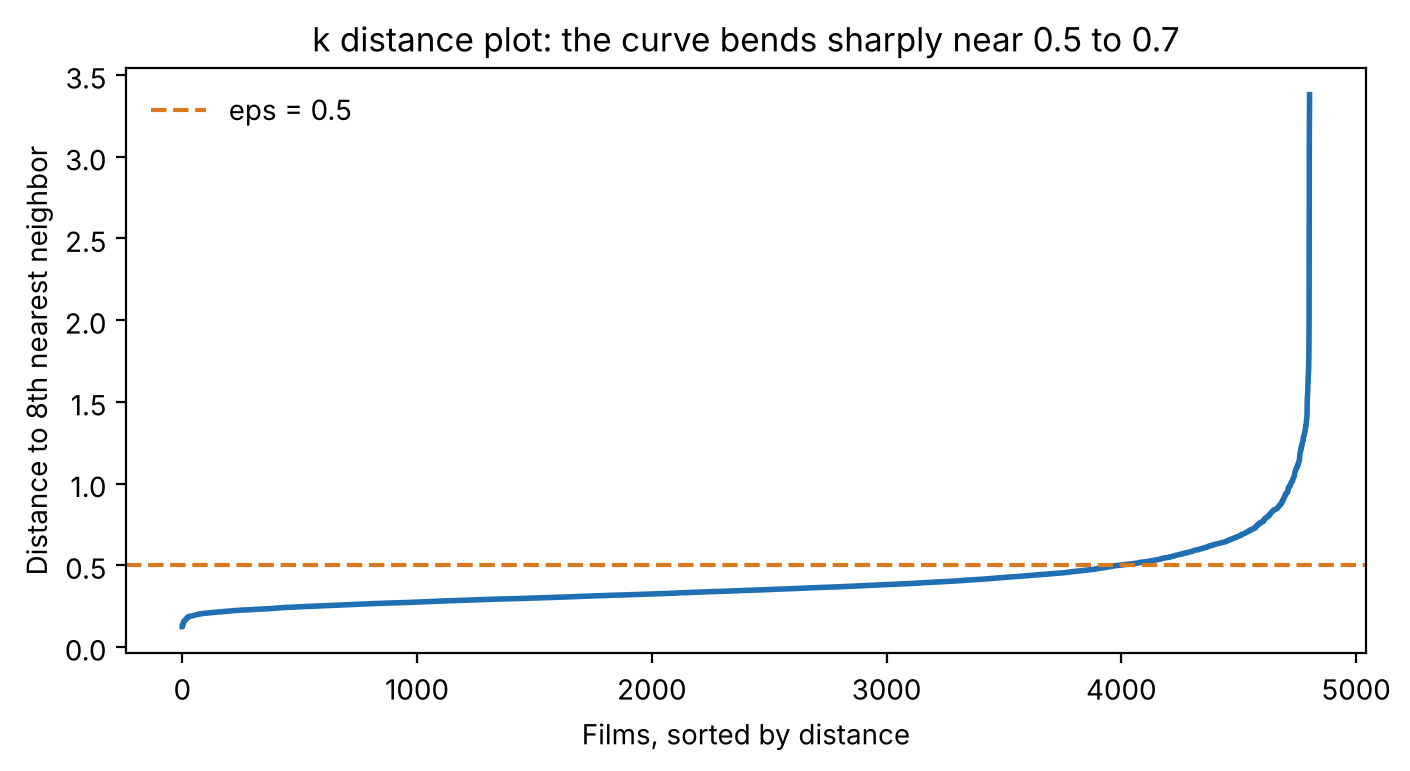

In [3]:
d8 = np.sort(NearestNeighbors(n_neighbors=8).fit(Z).kneighbors(Z)[0][:, -1])
plt.figure(figsize=(8, 3.8))
plt.plot(d8, color='#1f6fb2', linewidth=2)
plt.axhline(0.5, color='#d97a1f', linestyle='--', linewidth=1.5, label='eps = 0.5')
plt.xlabel('Films, sorted by distance'); plt.ylabel('Distance to 8th nearest neighbor')
plt.title('k distance plot: the curve bends sharply near 0.5 to 0.7')
plt.legend(frameon=False); plt.show()

In [4]:
rows = []
for eps in [0.2, 0.3, 0.4, 0.5, 0.7, 1.0]:
    lab = DBSCAN(eps=eps, min_samples=8).fit_predict(Z)
    sizes = pd.Series(lab[lab >= 0]).value_counts()
    rows.append({'eps': eps, 'clusters': len(sizes), 'noise_%': round((lab == -1).mean() * 100, 1),
                 'largest cluster sizes': sizes.head(3).tolist()})
pd.DataFrame(rows)

,eps,clusters,noise_%,largest cluster sizes
0,0.2,17,94.5,"[70, 23, 23]"
1,0.3,22,47.4,"[1577, 728, 21]"
2,0.4,5,18.0,"[3915, 7, 7]"
3,0.5,1,8.5,[4395]
4,0.7,1,2.4,[4686]
5,1.0,1,0.4,[4783]


With a small epsilon, most films are labeled noise and the rest break into many tiny clusters. At epsilon 0.3, DBSCAN finds two large clusters. From epsilon 0.5 up, everything dense joins **one** cluster and only the most isolated films are noise. Let's look at both.

In [5]:
lab03 = DBSCAN(eps=0.3, min_samples=8).fit_predict(Z)
big2 = pd.Series(lab03[lab03 >= 0]).value_counts().index[:2]
for c in big2:
    m = lab03 == c
    print(f'Cluster {c}: {m.sum()} films | median U.S. share {data.loc[m, "Domestic %"].median():.0f}% | '
          f'in English {data.loc[m, "Original_Language"].eq("en").mean():.0%} | median gross ${data.loc[m, "$Worldwide"].median()/1e6:.0f}M')

Cluster 0: 1577 films | median U.S. share 49% | in English 100% | median gross $115M
Cluster 4: 728 films | median U.S. share 0% | in English 8% | median gross $29M


In [6]:
lab05 = DBSCAN(eps=0.5, min_samples=8).fit_predict(Z)
noise = data[lab05 == -1]
print('Noise films at eps = 0.5:', len(noise), f'({len(noise) / len(data):.1%})')
print('Highest grossing noise films:', noise.sort_values('$Worldwide', ascending=False)['Release Group'].head(8).tolist())
print('Median log votes, noise vs. all films:', round(F.loc[lab05 == -1, 'log_votes'].median(), 2), 'vs.', round(F['log_votes'].median(), 2))

Noise films at eps = 0.5: 408 (8.5%)
Highest grossing noise films: ['Avengers: Endgame', 'Avatar', 'Avatar: The Way of Water', 'Spider-Man: No Way Home', 'Top Gun: Maverick', 'The Dark Knight', 'The Battle at Lake Changjin', 'Moana 2']
Median log votes, noise vs. all films: 4.77 vs. 6.96


DBSCAN's most useful output here is the **noise**. At epsilon 0.5 it flags 8.5% of films as outliers, and they are of two kinds: record breaking blockbusters (Avengers: Endgame, Avatar, Spider Man: No Way Home) and films with very few votes. k means would have forced all of them into a cluster.

## 2. Hierarchical agglomerative clustering (HAC): linkage methods

HAC starts with every film as its own cluster and keeps merging the two closest clusters. The **linkage** decides what "closest" means between two groups:
- **Single:** the closest pair of films
- **Complete:** the farthest pair
- **Average:** the average over all pairs
- **Ward:** the merge that adds the least within cluster variance (like k means)

I cut each tree at 3 clusters and compare with the Week 10 k means groups using the **adjusted Rand index** (ARI): 1 means identical groupings, 0 means no more alike than random.

In [7]:
rows = []
for link in ['ward', 'complete', 'average', 'single']:
    h = AgglomerativeClustering(n_clusters=3, linkage=link).fit_predict(Z)
    rows.append({'linkage': link, 'cluster sizes': sorted(np.bincount(h).tolist(), reverse=True),
                 'silhouette': round(silhouette_score(Z, h), 3), 'ARI vs. k means': round(adjusted_rand_score(kmeans3, h), 3)})
pd.DataFrame(rows)

,linkage,cluster sizes,silhouette,ARI vs. k means
0,ward,"[2095, 1889, 819]",0.257,0.518
1,complete,"[4060, 736, 7]",0.227,0.036
2,average,"[4750, 44, 9]",0.297,-0.000
3,single,"[4801, 1, 1]",0.593,0.000


The linkage changes everything. **Ward** gives three balanced groups that largely agree with k means (ARI about 0.5). **Single** linkage "chains" almost every film into one cluster and leaves two single films on their own. Its silhouette is the *highest*, which is misleading: splitting off two extreme films scores well, but tells us nothing. **Complete** and **average** fall in between, with one huge cluster and small outlier groups.

# Part 2: Content (MovieLens Tag Genome)

Same 20 PCA components of the 1,128 genome tags as in Week 10.

In [8]:
combo = pd.read_csv('combined_films.csv')
genome = pd.read_csv('genome_features.csv', index_col=0)
sub = combo.loc[X.index]
sub = sub[(sub['in_movielens'] == 1) & (sub['ml_n_ratings'] > 0) & sub['ml_movieId'].isin(genome.index)]
G = genome.loc[sub['ml_movieId'].astype(int)].set_index(sub.index)
Gp = PCA(n_components=20, random_state=42).fit_transform(StandardScaler().fit_transform(G))
kmeans6 = KMeans(n_clusters=6, n_init=10, random_state=42).fit_predict(Gp)

rows = []
for eps in [8, 10, 12, 14, 16]:
    lab = DBSCAN(eps=eps, min_samples=10).fit_predict(Gp)
    sizes = pd.Series(lab[lab >= 0]).value_counts()
    rows.append({'eps': eps, 'clusters': len(sizes), 'noise_%': round((lab == -1).mean() * 100, 1), 'largest cluster sizes': sizes.head(3).tolist()})
print('DBSCAN on content:')
print(pd.DataFrame(rows).to_string(index=False))
print()
for link in ['ward', 'average', 'single']:
    h = AgglomerativeClustering(n_clusters=6, linkage=link).fit_predict(Gp)
    print(f'HAC {link:8} sizes {sorted(np.bincount(h).tolist(), reverse=True)} | ARI vs. k means: {adjusted_rand_score(kmeans6, h):.3f}')

DBSCAN on content:
 eps  clusters  noise_% largest cluster sizes
   8         3     75.2         [511, 19, 10]
  10         2     57.9             [901, 17]
  12         2     40.8            [1262, 28]
  14         1     27.0                [1590]
  16         2     17.1             [1798, 9]

HAC ward     sizes [638, 623, 381, 320, 118, 99] | ARI vs. k means: 0.416
HAC average  sizes [2083, 34, 26, 15, 11, 10] | ARI vs. k means: 0.022
HAC single   sizes [2174, 1, 1, 1, 1, 1] | ARI vs. k means: 0.001


DBSCAN can't find content groups: at every epsilon it gives either mostly noise or one big cluster, because in 20 dimensions the films are spread evenly without dense pockets separated by gaps. Ward HAC again finds groups that partly agree with k means (ARI about 0.4).

## Dendrogram: how the top grossing films group by content

A dendrogram of the whole dataset would be unreadable, so here are the 30 highest grossing films in this set, merged with Ward linkage.

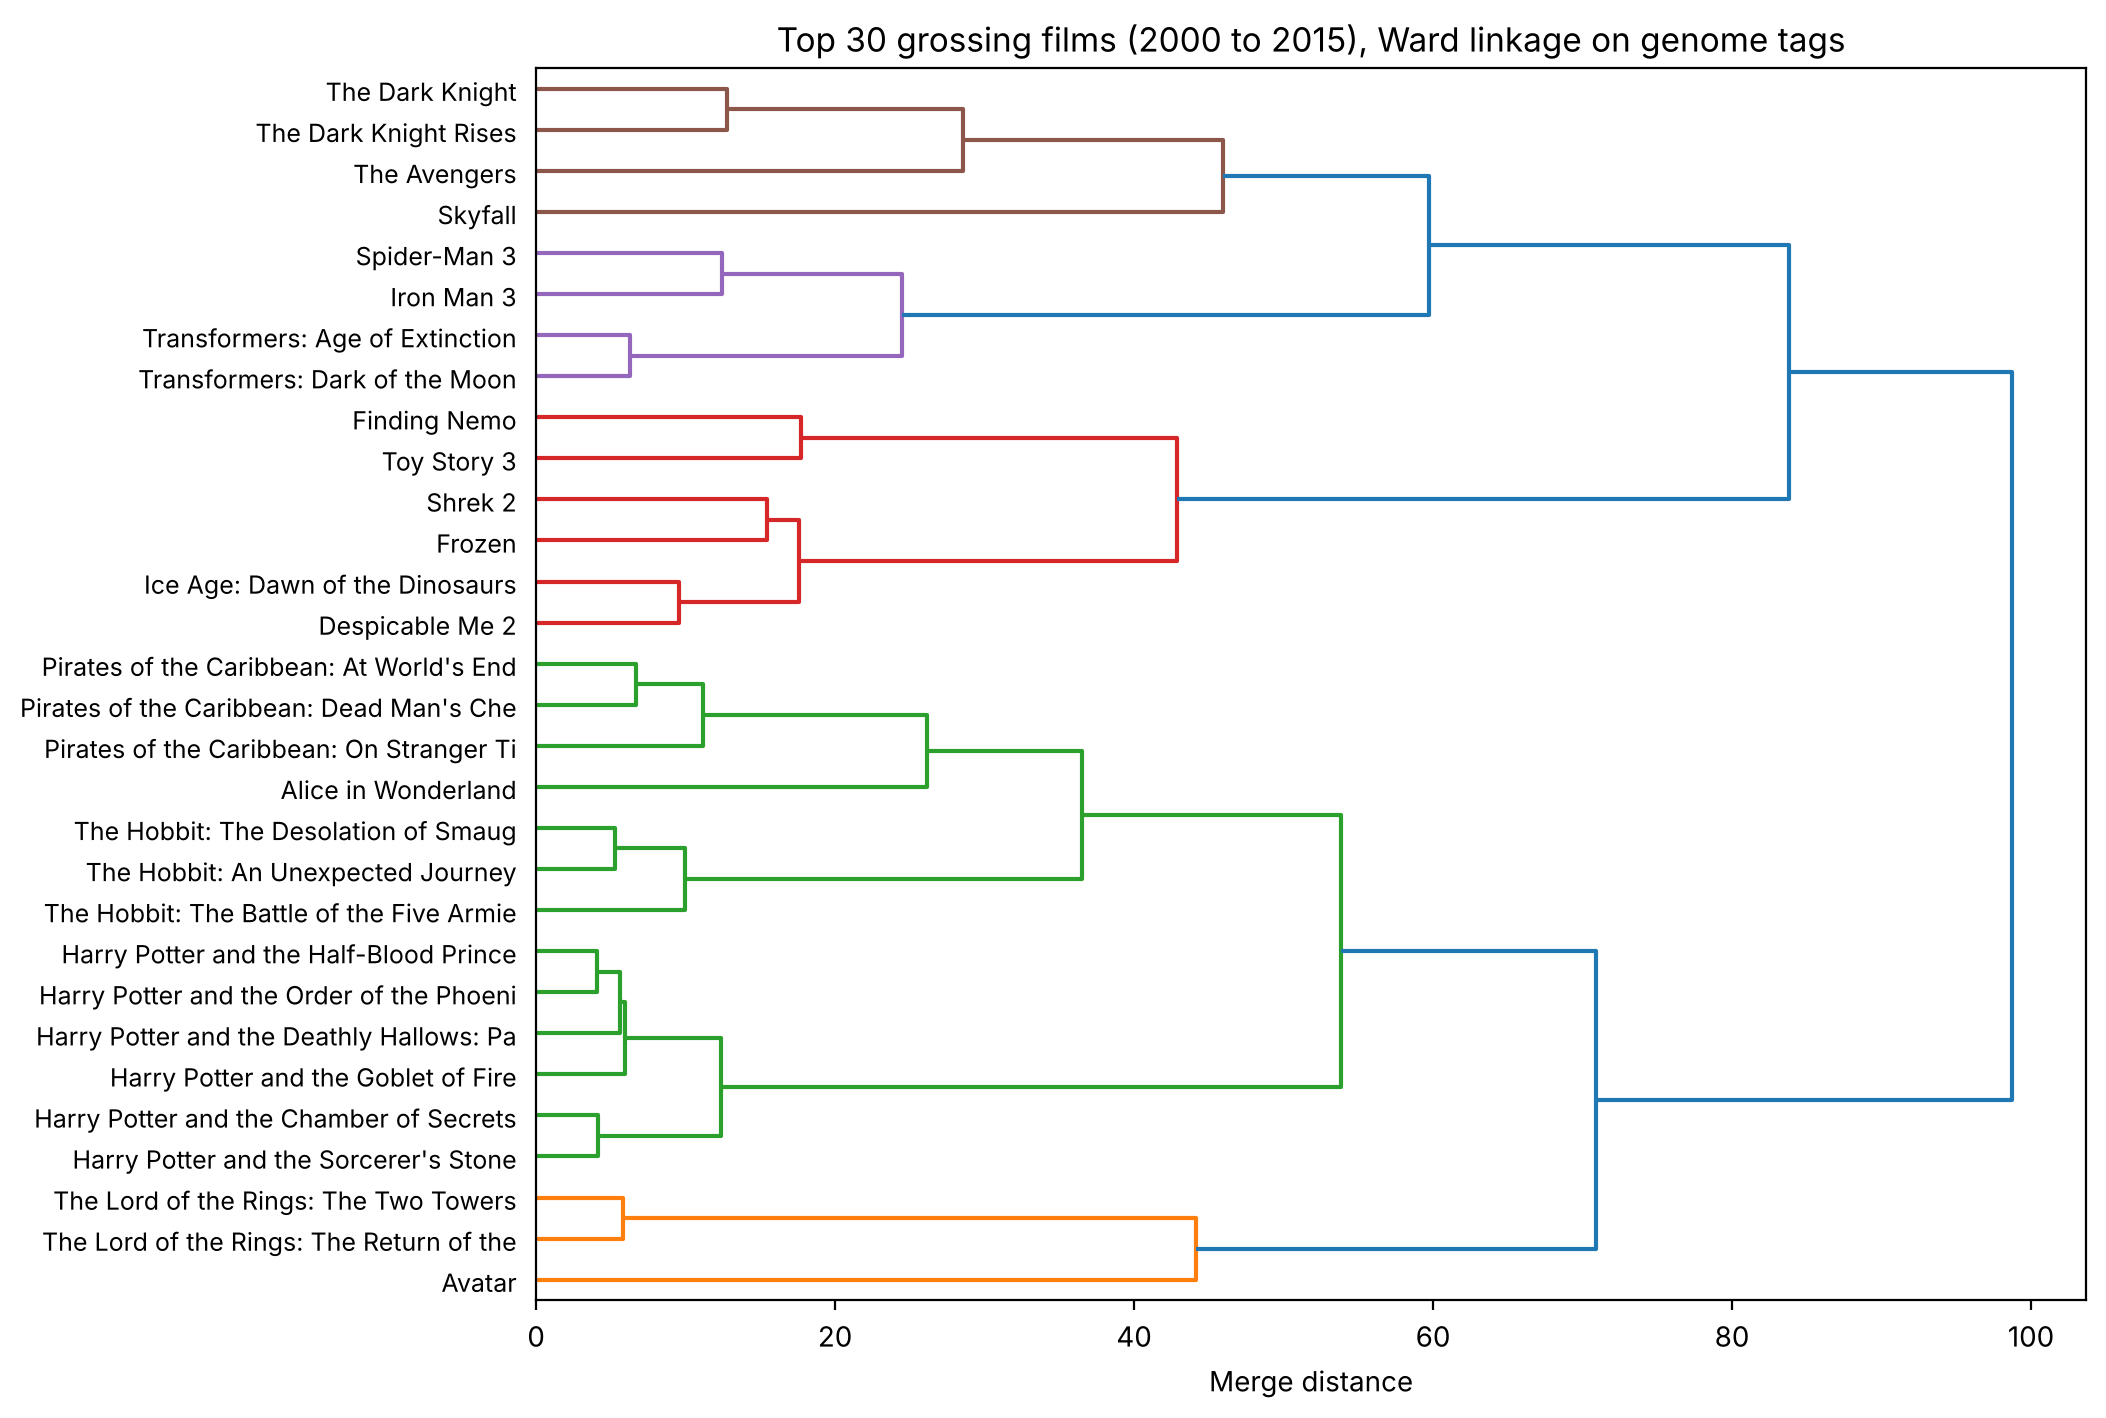

In [9]:
top30 = sub.sort_values('$Worldwide', ascending=False).index[:30]
pos = [sub.index.get_loc(i) for i in top30]
tree = linkage(Gp[pos], method='ward')
plt.figure(figsize=(10, 8))
dendrogram(tree, labels=sub.loc[top30, 'Release Group'].str.slice(0, 40).tolist(), orientation='right',
           color_threshold=0.6 * tree[:, 2].max(), leaf_font_size=9)
plt.title('Top 30 grossing films (2000 to 2015), Ward linkage on genome tags')
plt.xlabel('Merge distance'); plt.show()

# Conclusions

**DBSCAN finds outliers, not separate market groups.** The k distance plot bends at an epsilon of about 0.5 to 0.7. At 0.5, DBSCAN puts 91.5% of films into one dense cluster and labels 408 films (8.5%) as noise. Those outliers are of two kinds: record breaking blockbusters (Avengers: Endgame, Avatar, Spider Man: No Way Home) and films with very few votes. Only at a smaller epsilon (0.3) does it split off the group k means also found: 728 films with **no U.S. release**, only 8% in English, median gross $29M, separate from 1,577 English films with a U.S. release (median $115M). But at that epsilon almost half the films are noise. So the market groups from Week 10 are mostly regions of one continuous cloud of films, except for the international films, which really do form their own dense pocket.

**The linkage method matters more than anything else in HAC.** Ward linkage gave three balanced groups that agree fairly well with k means (adjusted Rand index 0.52). Single linkage chained 4,801 films into one cluster and left two films alone. It also had the *highest* silhouette score (0.59), which shows that a good silhouette can come from a useless split. Complete and average linkage gave one huge cluster plus small outlier groups.

**Content has no dense pockets.** On the genome tags, DBSCAN gave either mostly noise or one big cluster at every epsilon. Ward HAC agreed partly with the Week 10 k means content groups (adjusted Rand index 0.42). The dendrogram of the 30 top grossing films groups them in a way that makes sense: superhero and spy films, Marvel and Transformers style action, animation, fantasy franchises (Harry Potter, The Hobbit, Pirates of the Caribbean), and Lord of the Rings with Avatar. **Franchise and content type define the biggest earners.**

**Avoiding overfitting in clustering.** I chose epsilon from the k distance plot and MinPts from a standard rule (twice the number of features) instead of tuning them until the clusters looked nice, and I compared every result with the Week 10 k means groups instead of trusting the silhouette score alone.

### Think About It

- **How do epsilon and MinPts affect DBSCAN, and what goes wrong if they are poorly chosen?** A small epsilon or a large MinPts makes the "dense" bar hard to reach, so most points become noise and the rest break into many tiny clusters (94.5% noise at epsilon 0.2 here). A large epsilon or small MinPts makes everything connect, so all clusters merge into one (one cluster with 0.4% noise at epsilon 1.0). Both hide the real structure.
- **Why can different linkage methods give very different results on the same data?** They define the distance between groups differently. Single linkage only needs one close pair, so it chains clusters together through bridges of points, which is what happened here (4,801 films in one cluster). Complete linkage looks at the farthest pair, which keeps clusters compact but lets outliers sit in their own small groups. Ward minimizes added variance, so it makes round, balanced groups like k means.
- **When would you choose DBSCAN over HAC, or the reverse?** DBSCAN when clusters may have odd shapes, the number of clusters is unknown, and finding outliers matters, as with the blockbuster and low vote outliers here. HAC when you want to see how groups nest inside each other, choose the number of clusters afterward by cutting the tree, or explain the grouping with a dendrogram, as with the top 30 films. HAC is slow on very large datasets, since it compares all pairs.